# 3. Negotiating agents with several issues

**Examples of:**

- a negotiation protocol where agents exchange **packages**, each one knowing only its own scoring sheet;
- a concession on the **score** (time-dependent), instead of a concession on the price;
- two ways to choose a package with the same score: a **blind** agent and a **trade-off** agent;
- why looking at the other's offers leads to better agreements for **both**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from charging import *

## 3.1 The protocol

`negotiate(alice, bob)` runs a negotiation on the 3 issues of book 2:

1. offers **alternate**: Alice proposes a package at round 0, Bob at round 1, Alice at round 2, ...;
2. the other agent **accepts** if the offer is at least as good **for it** as the package it would propose now;
3. after $T = 20$ rounds without agreement: no deal, each agent keeps its reservation (30 for Alice, 25 for Bob).

A strategy is still a plain function `strategy(r, T, mine, theirs)`, but it now returns a **package**.
An agent only uses **its own** sheet: Alice's strategy never reads `BOB_SHEET`.

## 3.2 Conceding on the score

With one issue, an agent conceded on the price.   
With several issues, it concedes on its **score**:
- at round $r$ it asks for a **target score**, going from its best score down to its reservation, with the time-dependent formula.

---

**Exercise 1**.
- Write a function `target(r, T, sheet, best, reservation, beta)` using `time_dependent` (you do not need the sheet variable).  
It returns the next price according to the strategy.
- Plot the target of Alice (from 75 to 30) and of Bob (from 70 to 25) over the 20 rounds, with $\beta = 1$.
- At which round does Alice's target fall below 53, her score in the Nash package?

In [2]:
# Exercise 1: your code here

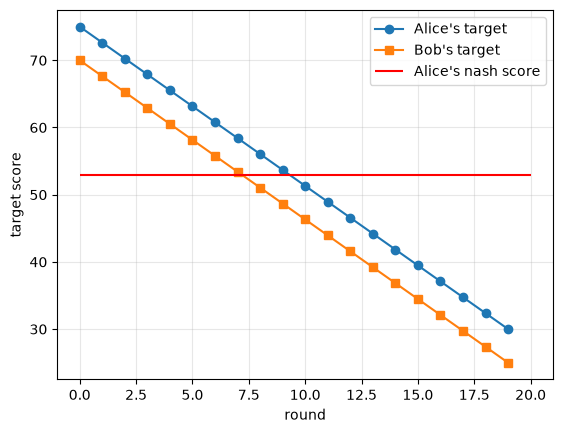

Alice's target is below 53 from round 10


In [ ]:
#SOLUTION

def target(r, T, sheet, best, reservation, beta):
#TODO

T = T_PACKAGES
alice_targets = [target(r, T, ALICE_SHEET, 75, ALICE_RESERVATION_3, 1) for r in range(T)]
bob_targets = [target(r, T, BOB_SHEET, 70, BOB_RESERVATION_3, 1) for r in range(T)]
plt.plot(alice_targets, "o-", label="Alice's target")
plt.plot(bob_targets, "s-", label="Bob's target")
plt.hlines(y=53, xmin=0, xmax=T, colors="r", label="Alice's nash score")
plt.xlabel("round"); plt.ylabel("target score"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("Alice's target is below 53 from round", next(r for r in range(T) if alice_targets[r] < 53))

> **Reading.** The targets decrease linearly. Alice asks less than 53 from round 10: if Bob offers the Nash package then, she accepts.

---

## 3.3 A blind agent

Many packages reach the target score. A first idea: propose the package with the **lowest score above the target**
(the agent concedes exactly as planned), **without looking** at the other's offers.

**Exercise 2**.
- Write a function `blind_offer(r, T, sheet, best, reservation, beta)` that returns, among the packages of `all_packages(ISSUES_3)`
with a score ≥ the target, the one with the **lowest** score.
- Build Alice's and Bob's strategies with `lambda`, run `negotiate`, and draw the negotiation with
`show_negotiation(result, ALICE_RESERVATION_3, BOB_RESERVATION_3)`.
- Where is the deal compared with the Pareto frontier?

In [ ]:
# Exercise 2: your code here
def blind_offer(r, T, sheet, best, reservation, beta):
#TODO

alice_blind = lambda r, T, mine, theirs: blind_offer(r, T, ALICE_SHEET, 75, ALICE_RESERVATION_3, 1)
bob_blind = lambda r, T, mine, theirs: blind_offer(r, T, BOB_SHEET, 70, BOB_RESERVATION_3, 1)


In [ ]:
result = negotiate(alice_blind, bob_blind)
print("deal:", result["package"], "at round", result["round"], "| scores", result["scores"])
show_negotiation(result, ALICE_RESERVATION_3, BOB_RESERVATION_3, title="two blind agents")

deal: {'margin': 0.04, 'charges': 6, 'slot': '7h-18h'} at round 11 | scores (50, 44)


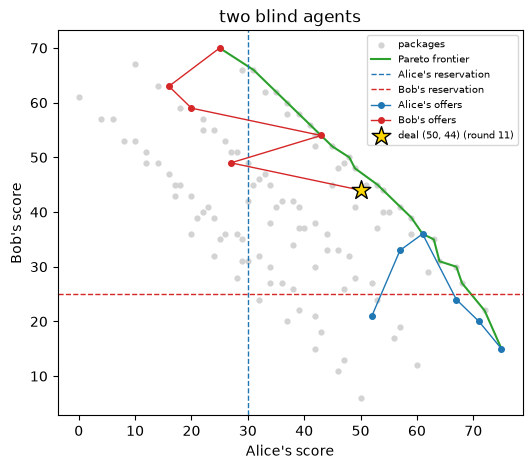

> **Reading.**
> - Deal at round 11 with scores (50, 44): margin 0.04 EUR/kWh, only 6 charges, day slot.
> - The slot is the right one (both prefer the day, so even blind agents find it), but the deal is **below** the Pareto frontier:
> for instance (54, 44) was better for Alice and as good for Bob (margin 0.08, 8 charges).
> - Each blind agent proposes packages that are good for itself, but often needlessly bad for the other:
> many offers are far below the frontier.

---

## 3.4 A trade-off agent

Second idea (Faratin, Sierra and Jennings, 2002): among the packages that reach my target, propose the one **closest to the other's last offer**.   
The agent still does not know the other's sheet, but its offers tell something about it.

`option_distance(p, q)` measures how far two packages are (0 = the same package).

**Exercise 3**.
- Write a function `closest_offer(r, T, theirs, sheet, best, reservation, beta)`:
  - at the first round (`theirs` is empty), propose the best package for yourself;
  - then, among the packages with a score ≥ the target, propose the one with the smallest `option_distance` to `theirs[-1]`.
- Run a negotiation between two trade-off agents, and draw it. Compare with exercise 2.

In [ ]:
# Exercise 3: your code here
def closest_offer(r, T, theirs, sheet, best, reservation, beta):
#TODO

alice_trade = lambda r, T, mine, theirs: closest_offer(r, T, theirs, ALICE_SHEET, 75, ALICE_RESERVATION_3, 1)
bob_trade = lambda r, T, mine, theirs: closest_offer(r, T, theirs, BOB_SHEET, 70, BOB_RESERVATION_3, 1)



In [ ]:
result = negotiate(alice_trade, bob_trade)
print("deal:", result["package"], "at round", result["round"], "| scores", result["scores"])
show_negotiation(result, ALICE_RESERVATION_3, BOB_RESERVATION_3, title="two trade-off agents");

deal: {'margin': 0.1, 'charges': 10, 'slot': '7h-18h'} at round 11 | scores (53, 45)


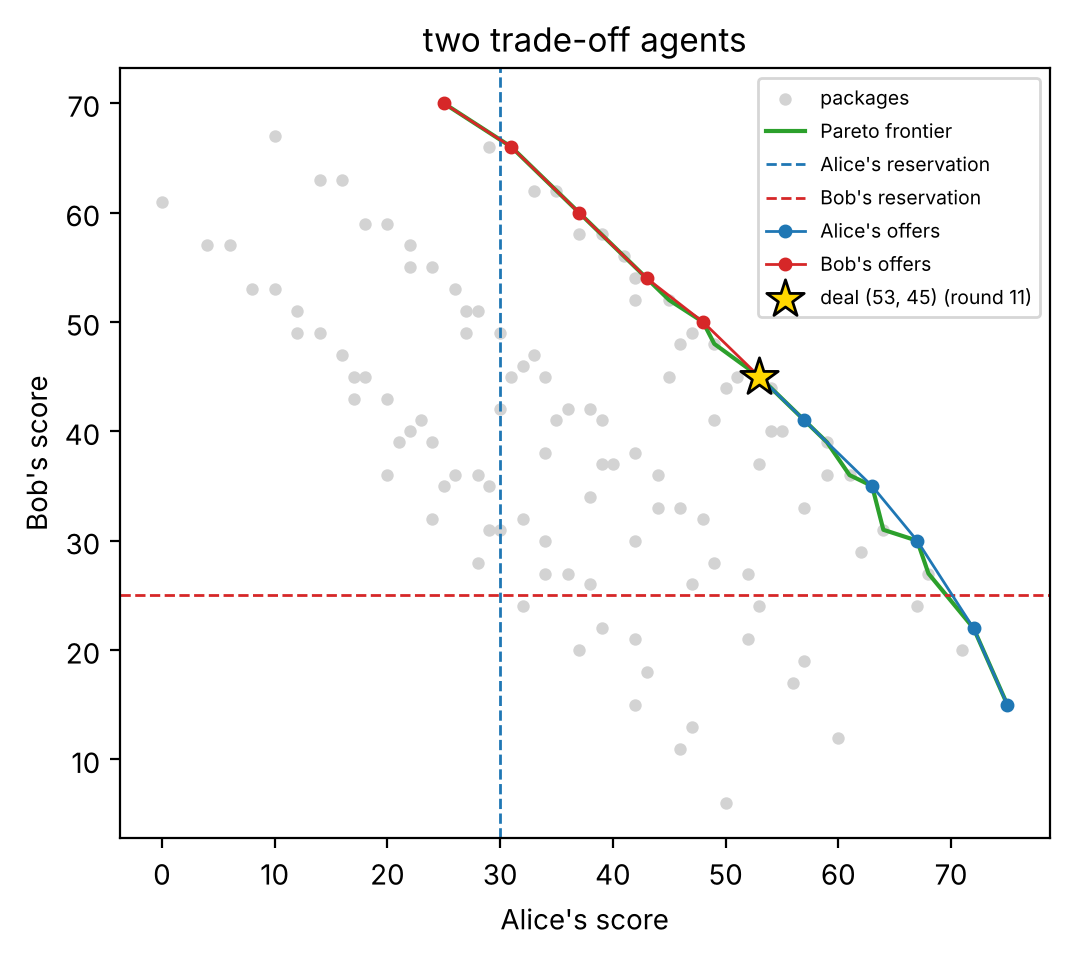

> **Reading.**
> - Deal at round 11 with scores **(53, 45)**: margin 0.10 EUR/kWh, 10 charges, day slot.   
This is exactly the **Nash package** of book 2!
> - The two agents concede at the same speed as the blind agents, but they choose packages **close to each other**:  
> the offers move along the Pareto frontier, and both gain more.
> - Neither agent knows the other's sheet: the offers carry enough information to find the logrolling.

---

## 3.5 Mixed pairs

`charging.py` contains the two strategies, written as in exercises 2 and 3: `blind(r, T, mine, theirs, sheet, issues, reservation, beta)` and `trade_off(...)` (same parameters).

**Exercise 4**.
- Run the four pairs blind/blind, trade-off/trade-off, blind Alice/trade-off Bob, trade-off Alice/blind Bob ($\beta = 1$).
- For each one, print the deal round, the scores, the sum of the scores and the Nash product $(s_A - 30)(s_B - 25)$.

In [8]:
# Exercise 4: your code here

Alice blind     / Bob blind    : round 11, scores (50, 44), sum 94, Nash product 380
Alice blind     / Bob trade-off: round 14, scores (42, 52), sum 94, Nash product 324
Alice trade-off / Bob blind    : round 11, scores (50, 44), sum 94, Nash product 380
Alice trade-off / Bob trade-off: round 11, scores (53, 45), sum 98, Nash product 460


> **Reading.**
> - Two trade-off agents reach the best result (sum 98, Nash product 460).
> - Facing a blind Alice, the trade-off Bob does better than a blind Bob (52 instead of 44), but the deal is not on the frontier, and comes late (round 14).
> - Facing a blind Bob, the trade-off Alice cannot do much: Bob's offers do not move towards her, "being close to them" gives no useful information.
> - Trade-off works best when **both** agents use it: each one makes its offers informative for the other.

---

**Exercise 5** *(explore)*.
- Keep two trade-off agents but change their patience: Boulware ($\beta = 0.3$) or Conceder ($\beta = 3$).
- Who wins? Is the deal still on the Pareto frontier? Is there still a deal before the deadline?

In [10]:
# Exercise 5: your code here

Alice beta=1, Bob beta=1: scores (53, 45), round 11, {'margin': 0.1, 'charges': 10, 'slot': '7h-18h'}
Alice beta=0.3, Bob beta=3: scores (63, 35), round 13, {'margin': 0.12, 'charges': 8, 'slot': '7h-18h'}
Alice beta=3, Bob beta=0.3: scores (37, 60), round 13, {'margin': 0.0, 'charges': 8, 'slot': '7h-18h'}
Alice beta=0.3, Bob beta=0.3: scores (53, 45), round 16, {'margin': 0.1, 'charges': 10, 'slot': '7h-18h'}


> **Reading.**  
> - As with one issue, the Boulware agent gets the larger score: (63, 35) or (37, 60).  
> - But the deals are still **on** the Pareto frontier (day slot, 8 charges):  
> patience decides **how the value is shared**, the trade-off decides **how much value is created**.  
> Two Boulware agents still find the Nash package, but late (round 16).

---

## Key points

| Idea | . |
|---|---|
| protocol | alternating packages; accept if at least as good as my own next offer; deadline 20 rounds |
| conceding | on the **target score**, from the best score to the reservation |
| blind agent | lowest score above the target: (50, 44), below the Pareto frontier |
| trade-off agent | closest to the other's last offer: (53, 45), the Nash package |
| information | no agent reads the other's sheet: the offers carry the information |